# Анализ BCR

## Imports

In [1]:
from pathlib import Path
from collections import Counter
import gzip
import os
import sys
import subprocess
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from repseq import io as repseqio
from repseq import stats
from repseq import clone_filter as clf
from repseq import plot as rsplot

stats.AA_PROPS_PATH = str(Path(stats.__file__).parent / "resourses" / "aa_property_table.txt")

## WORKING DIR

In [2]:
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "environment.yml").is_file() and (p / "notebooks").is_dir())
WORKING_DIR = PROJECT_ROOT / "outputs" / "bcr"
MIXCR_DIR = WORKING_DIR / "mixcr_umi"
MIXCR_DIR.mkdir(parents=True, exist_ok=True)
fastq_files = sorted((PROJECT_ROOT / "data" / "bcr").glob("*.fastq.gz"))
r1, r2 = fastq_files
print(r1.name, r2.name, sep="\n")

DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz
DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz


## Проверка FASTQ

Проверяем парность и длину прочтений. В R1 ищем якорь UMI-пресета в первых трёх позициях. Качество оцениваем по первым 10 000 парам.

In [3]:
lengths = [Counter(), Counter()]
qualities = [Counter(), Counter()]
n_bases = [0, 0]
pairs = 0
anchor_matches = 0
with gzip.open(r1, "rt") as f1, gzip.open(r2, "rt") as f2:
    while True:
        headers = [f1.readline(), f2.readline()]
        if not any(headers):
            break
        assert all(headers)
        assert headers[0].split()[0].removesuffix("/1") == headers[1].split()[0].removesuffix("/2")
        for i, handle in enumerate([f1, f2]):
            sequence = handle.readline().strip()
            separator = handle.readline()
            quality = handle.readline().strip()
            assert headers[i].startswith("@") and separator.startswith("+")
            assert sequence and len(sequence) == len(quality)
            assert set(sequence) <= set("ACGTN")
            if i == 0 and sequence.find("TGGTATCAACGCAGAGT", 0, 19) >= 0:
                anchor_matches += 1
            lengths[i][len(sequence)] += 1
            n_bases[i] += sequence.count("N")
            if pairs < 10000:
                qualities[i].update(quality)
        pairs += 1

fastq_stats = pd.DataFrame({
    "read": ["R1", "R2"],
    "records": [pairs, pairs],
    "min_length": [min(x) for x in lengths],
    "max_length": [max(x) for x in lengths],
    "N_bases": n_bases,
    "Q30_fraction_first_10000": [sum(n for q, n in x.items() if ord(q)-33 >= 30) / sum(x.values()) for x in qualities],
})
fastq_stats.to_csv(WORKING_DIR / "fastq_stats.csv", index=False)
fastq_stats

,read,records,min_length,max_length,N_bases,Q30_fraction_first_10000
0,R1,938889,251,251,0,0.903193
1,R2,938889,251,251,69914,0.756911


In [4]:
print(f"Якорь UMI-пресета найден в {anchor_matches:,} парах ({anchor_matches/pairs:.2%})")

Якорь UMI-пресета найден в 899,815 парах (95.84%)


Получено 938 889 пар. Все записи имеют длину 251 нуклеотид, идентификаторы пар совпадают. В R1 нет N, в R2 найдено 69 914 N. Доля Q30 в первых 10 000 парах равна 90,3% для R1 и 75,7% для R2 (качество R2 ниже)

## Протокол и UMI

Используем `milab-human-rna-ig-umi-multiplex` из MiXCR 4.7.0. Якорная последовательность пресета совпала с R1 у 95,84% пар. Пресет извлекает следующую за якорем метку UMI длиной 14 нуклеотидов и выполняет её коррекцию

## MiXCR

In [5]:
mixcr = Path(sys.executable).parent / "mixcr"
mixcr_env = os.environ.copy()
mixcr_env["PATH"] = str(mixcr.parent) + os.pathsep + mixcr_env.get("PATH", "")
version_check = subprocess.run([str(mixcr), "--version"], env=mixcr_env,
                               capture_output=True, text=True)
license_ready = version_check.returncode == 0
print(version_check.stdout)
print(version_check.stderr)
(MIXCR_DIR / "version_check.log").write_text(version_check.stdout + version_check.stderr)

MiXCR v4.7.0 (built Wed Aug 07 22:19:48 MSK 2024; rev=976ba14139; branch=no_branch; host=fv-az1019-185)
RepSeq.IO v2.5.0 (rev=06fa1852ee)
MiLib v3.5.0 (rev=b6cfcdc2af)
Built-in V/D/J/C library: repseqio.v5.1

Library search path:
- built-in libraries
- /home/anna/Bioinformatics305/homework_immune/notebooks/.




310

## Обработка MiXCR

In [6]:
assert license_ready, "Проверьте доступность MiXCR"
sample = "DChu_T7_pbmc_d7COVID2_2"
preset = "milab-human-rna-ig-umi-multiplex"
prefix = MIXCR_DIR / sample
clns = Path(str(prefix) + ".clns")
clone_file = Path(str(prefix) + ".clones_IGH.tsv")
analyze_command = [str(mixcr), "-Xmx4g", "-XX:ActiveProcessorCount=4", "analyze", preset, "--threads", "4",
                   "--use-local-temp", str(r1), str(r2), str(prefix)]
print(" ".join(analyze_command))
(MIXCR_DIR / "analyze_command.json").write_text(json.dumps(analyze_command, indent=2))
if not clone_file.is_file():
    with (MIXCR_DIR / "analyze.log").open("w") as log:
        subprocess.run(analyze_command, env=mixcr_env, stdout=log, stderr=subprocess.STDOUT, check=True)
assert clns.is_file() and clone_file.is_file()

/home/anna/miniconda3/envs/immune-mixcr/bin/mixcr -Xmx4g -XX:ActiveProcessorCount=4 analyze milab-human-rna-ig-umi-multiplex --threads 4 --use-local-temp /home/anna/Bioinformatics305/homework_immune/data/bcr/DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz /home/anna/Bioinformatics305/homework_immune/data/bcr/DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz /home/anna/Bioinformatics305/homework_immune/outputs/bcr/mixcr_umi/DChu_T7_pbmc_d7COVID2_2


In [7]:
align_report = json.loads(Path(str(prefix) + ".align.report.json").read_text())
assemble_report = json.loads(Path(str(prefix) + ".assemble.report.json").read_text())
refine_report = json.loads(Path(str(prefix) + ".refine.report.json").read_text())
clones = pd.read_csv(clone_file, sep="\t")
assert len(clones) == assemble_report["clones"]
assert clones.readCount.sum() == assemble_report["readsInClones"]
processing_stats = pd.Series({
    "Исходные пары": pairs,
    "Распознан рисунок меток": align_report["tagParsingReport"]["matched"],
    "Успешно выровнены": align_report["aligned"],
    "Вошли в клонотипы": int(clones.readCount.sum()),
}, name="Пары").to_frame()
processing_stats["% от исходных пар"] = (100 * processing_stats["Пары"] / pairs).round(2)
display(processing_stats)
umi_filter = refine_report["correctionReport"]["filterReport"]
print("UMI-группы после коррекции", umi_filter["numberOfGroups"])
print("UMI-группы после фильтра", umi_filter["numberOfGroupsAccepted"])
print(Path(str(prefix) + ".qc.txt").read_text())

,Пары,% от исходных пар
Исходные пары,938889,100.00
Распознан рисунок меток,935789,99.67
Успешно выровнены,865681,92.20
Вошли в клонотипы,716879,76.35


UMI-группы после коррекции 163191
UMI-группы после фильтра 103842

  Successfully aligned reads:                           92.2%  [OK]
  Off target (non TCR/IG) reads:                        0.96%  [OK]
  Reads with no V or J hits:                            5.32%  [OK]
  Reads with no barcode:                                0.33%  [OK]
  Overlapped paired-end reads:                          93.92% [OK]
  Alignments that do not cover CDR1_TO_FR4:             2.84%  [OK]
  Tag groups that do not cover CDR1_TO_FR4:             0.12%  [OK]
  Barcode collisions in clonotype assembly:             2.73%  [WARN]
  Unassigned alignments in clonotype assembly:          1.67%  [OK]
  Reads used in clonotypes:                             91.59% [OK]
  Alignments dropped due to low sequence quality:       0.0%   [OK]
  Clones dropped in post-filtering:                     0.0%   [OK]
  Alignments dropped in clones post-filtering:          0.0%   [OK]
  Reads dropped in tags error correction and fi

Шаблон меток распознан у 99,67% пар. Успешно выровнено 865 681 пар (92,20%). В клонотипы вошло 716 879 пар (76,35% исходных данных).

Получено 37 516 клонотипов IGH и 90 924 UMI в них. После фильтра функциональности остаются 36 416 клонотипов и 89 665 UMI. IGK и IGL в экспорте отсутствуют.

Фильтр поддержки UMI оставил 103 842 групп из 163 191. В отчёте QC отмечены потери при фильтрации UMI и конфликты меток при сборке

## Загрузка клонотипов

In [8]:
clonoset_rows = []
export_counts = []
for chain in ["IGH", "IGK", "IGL"]:
    filename = Path(str(prefix) + f".clones_{chain}.tsv")
    if not filename.is_file():
        export_counts.append({"chain": chain, "clonotypes": 0})
        continue
    table = pd.read_csv(filename, sep="\t")
    export_counts.append({"chain": chain, "clonotypes": len(table)})
    if len(table):
        clonoset_rows.append({"sample_id": chain, "chain": chain, "filename": str(filename)})
clonosets_bcr = pd.DataFrame(clonoset_rows)
assert len(clonosets_bcr) > 0
pd.DataFrame(export_counts)

,chain,clonotypes
0,IGH,37516
1,IGK,0
2,IGL,0


In [9]:
example = repseqio.read_clonoset(clonosets_bcr.iloc[0]["filename"])
assert "uniqueMoleculeCount" in example.columns
example[["cloneId", "readCount", "uniqueMoleculeCount", "aaSeqCDR3"]].head()

,cloneId,readCount,uniqueMoleculeCount,aaSeqCDR3
0,1,5023,445,CAHSPASQGHFLMTFGGLIIPHFDSW
1,0,4928,645,CARDRRTGLWSGYGYMDVW
2,6,3042,255,CAHSSDIIGGSWGFGMDVW
3,4,3010,353,CARDPNYDFWSGGDMNVW
4,5,2777,339,CTTDLDYYDSSGYRFDCW


В экспорте есть оба счётчика. `readCount` хранит число прочтений, `uniqueMoleculeCount` число UMI

## Have a look at clonosets contents

In [10]:
clonoset_stats_bcr = stats.calc_clonoset_stats(clonosets_bcr, cpu=2)
clonoset_stats_bcr.set_index("sample_id")[["clones", "clones_func", "reads", "reads_func", "umi", "umi_func"]].T

Using 2 cores


CalcClonosetStats |##################################################| 1/1 calcultaion(s) processed


sample_id,IGH
clones,37516
clones_func,36416
reads,716879
reads_func,706820
umi,90924
umi_func,89665


## Filters

In [11]:
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter

## CDR3 properties

In [12]:
cdr3_properties = stats.calc_cdr3_properties(clonosets_bcr, cl_filter=func_filter, cpu=2)
cdr3_properties.set_index("sample_id")[["mean_cdr3nt_len", "mean_insert_size", "zero_insert_freq"]].T.round(3)

Using 2 cores


CalcCDR3aaProperties |##################################################| 1/1 calcultaion(s) processed


sample_id,IGH
mean_cdr3nt_len,54.231
mean_insert_size,13.003
zero_insert_freq,0.011


## CDR3len distributions

Using 2 cores


CalcCDR3LengthDistribution |##################################################| 1/1 calcultaion(s) processed


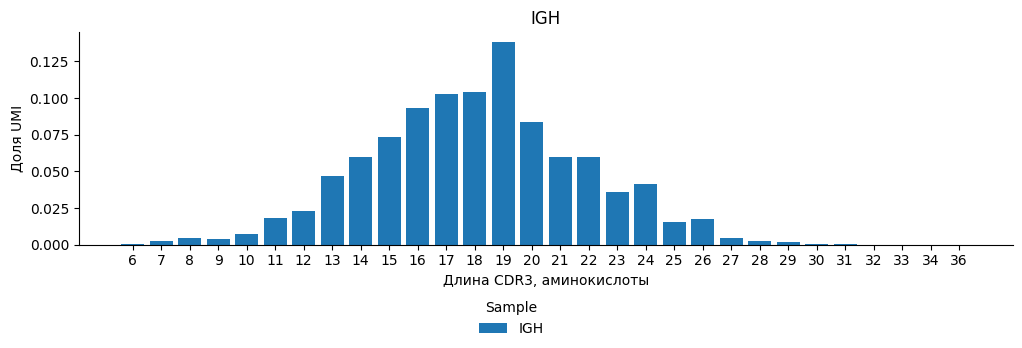

In [13]:
cdr3_len_distribs = stats.cdr3_length_distributions(
    clonosets_bcr, cl_filter=func_filter, cpu=2, count_by_freq=True,
    seq_type="aa", table="long", zero_fill=True)
fig = rsplot.cdr3_length_distributions(cdr3_len_distribs, height=3.5)
fig.set_size_inches(10, 3.5)
fig.axes[0].set(xlabel="Длина CDR3, аминокислоты", ylabel="Доля UMI")
fig

Максимум распределения приходится на 19 аминокислот. Средняя длина вставок равна 13,00 нуклеотида.

## Segment usage

### V-usage

Using 2 cores


CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


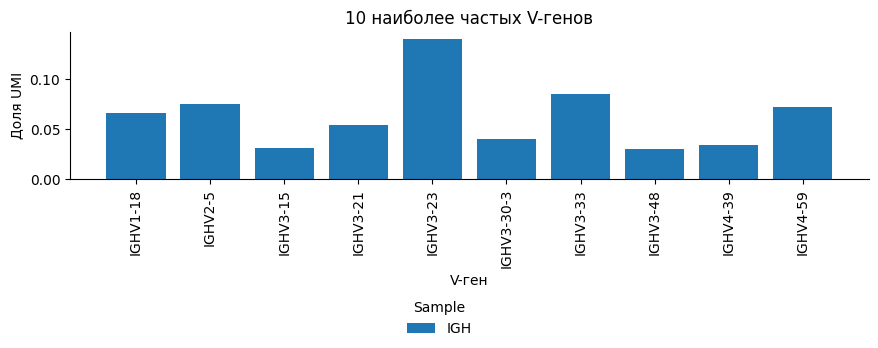

In [14]:
v_usage = stats.calc_segment_usage(clonosets_bcr, segment="v", cl_filter=func_filter, table="long", cpu=2)
v_top = v_usage.nlargest(10, "usage")
fig = rsplot.segment_usage(v_top, plot_type="barplot", height=3.5, aspect=2)
fig.set_size_inches(9, 3.5)
fig.axes[0].set(title="10 наиболее частых V-генов", xlabel="V-ген", ylabel="Доля UMI")
fig

На графике показаны 10 наиболее частых V-генов

### J-usage

Using 2 cores


CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


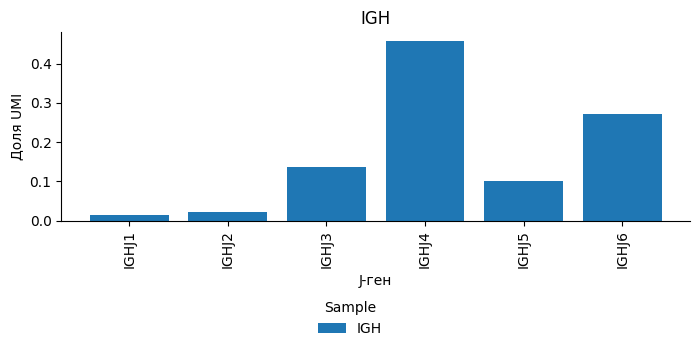

In [15]:
j_usage = stats.calc_segment_usage(clonosets_bcr, segment="j", cl_filter=func_filter, table="long", cpu=2)
fig = rsplot.segment_usage(j_usage, plot_type="barplot", height=3.5, aspect=2)
fig.set_size_inches(7, 3.5)
fig.axes[0].set(xlabel="J-ген", ylabel="Доля UMI")
fig

Наиболее частые V-гены: IGHV3-23 (~14%), IGHV3-33 (~9%), IGHV2-5 (~8%). Среди J-генов преобладают IGHJ4 (~46%), IGHJ6 (~27%). Доли рассчитаны по UMI после фильтра функциональности.

### C-usage и изотипы

C-ген определяет изотип тяжёлой цепи. Считаем его использование аналогично V и J.

Using 2 cores


CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


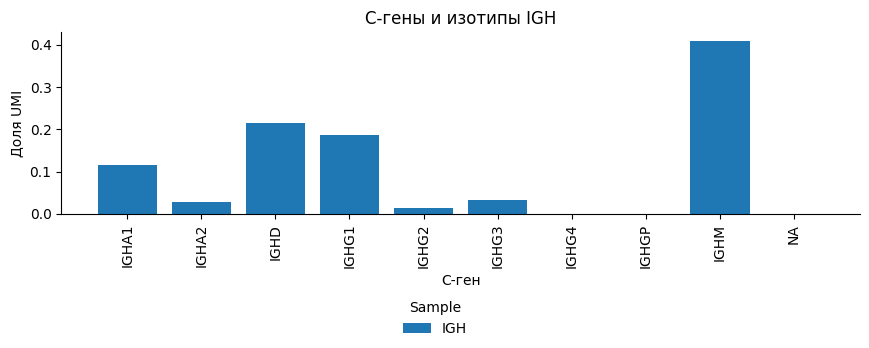

In [16]:
c_usage = stats.calc_segment_usage(clonosets_bcr, segment="c", cl_filter=func_filter, table="long", cpu=2)
fig = rsplot.segment_usage(c_usage, plot_type="barplot", height=3.5, aspect=2)
fig.set_size_inches(9, 3.5)
fig.axes[0].set(title="C-гены и изотипы IGH", xlabel="C-ген", ylabel="Доля UMI")
fig

Наибольшие доли приходятся на IGHM (~40%), IGHD (~20%), IGHG1 (~18%), IGHA1 (~11%). IGHM соответствует IgM, IGHD соответствует IgD, IGHG1 соответствует IgG1, IGHA1 соответствует IgA1 (доли описывают состав молекул РНК в библиотеке)

## Convergence

In [17]:
convergence = stats.calc_convergence(clonosets_bcr, cl_filter=func_filter, iterations=1, cpu=2)
convergence.set_index("sample_id")[["convergence", "convergence_v", "convergence_vj"]].T.round(4)

CalcConvergence: for the most honest comparison, use a filter with equal downsampling for all samples. This is preferred to top=N filters and much preferred to calculations without normalization.
CalcConvergence settings: seed=None, downsample=None, top=None, iterations=1
Using 2 cores


CalcConvergence |##################################################| 1/1 calcultaion(s) processed


sample_id,IGH
convergence,1.0077
convergence_v,1.0075
convergence_vj,1.0074


Convergence равна 1,0077, с учётом V и J равна 1,0074. Число уникальных CDR3nt лишь немного превышает число CDR3aa. В BCR на это соотношение могут влиять синонимичные соматические мутации. Разные строки клонотипов также могут иметь одну CDR3, поскольку сборка учитывает CDR1_TO_FR4 и C-ген.

## Diversity stats

In [18]:
diversity_stats = stats.calc_diversity_stats(clonosets_bcr, cl_filter=func_filter, iterations=1, cpu=2)
diversity_stats.set_index("sample_id")[["diversity", "shannon_wiener", "clonality", "chao1", "berger_parker", "d50"]].T.round(4)

CalcDiversityStats: for the most honest comparison, use a filter with equal downsampling for all samples. This is preferred to top=N filters and much preferred to calculations without normalization.
CalcDiversityStats settings: seed=None, downsample=None, top=None, iterations=1
Using 2 cores


CalcDiversityStats |##################################################| 1/1 calcultaion(s) processed


sample_id,IGH
diversity,36416.0000
shannon_wiener,9.3256
clonality,0.1121
chao1,73101.5018
berger_parker,0.0072
d50,0.0671


Крупнейший клонотип даёт 0,72% UMI, 6,71% клонотипов дают половину UMI.

Оценка Chao1 чувствительна к редким клонотипам. Здесь 67,18% функциональных клонотипов имеют одну UMI.

## Rarefaction

Using 2 cores


CalcRarefactionPoints |##################################################| 1/1 calcultaion(s) processed


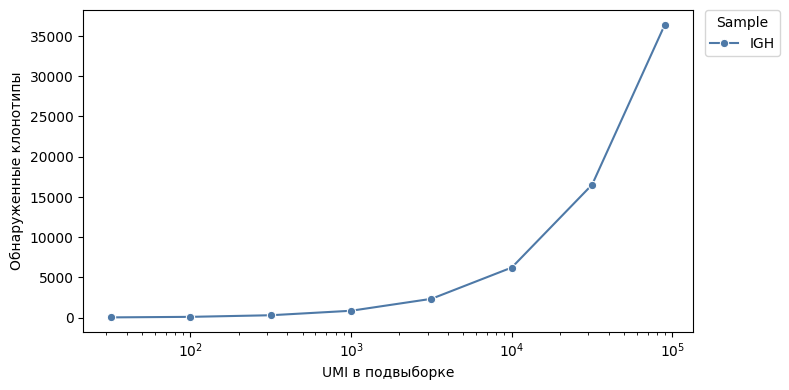

In [19]:
rarefaction_points = stats.calc_rarefaction_curve(clonosets_bcr, cl_filter=func_filter, iterations=3, seed=100, cpu=2)
fig = rsplot.rarefaction_curve(rarefaction_points, log_x=True, aspect=2, height=4)
fig.axes[0].set(xlabel="UMI в подвыборке", ylabel="Обнаруженные клонотипы")
fig

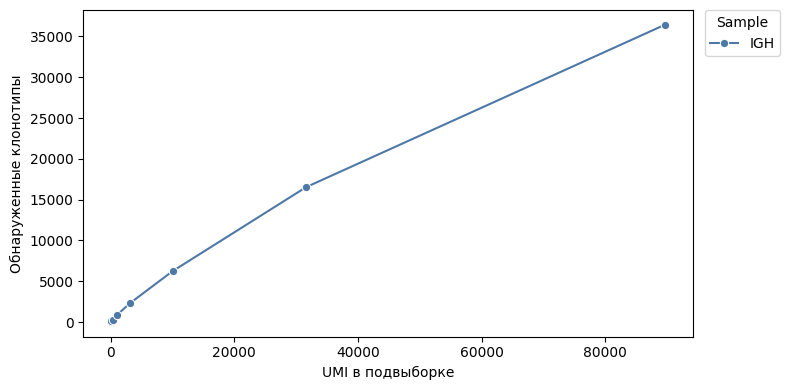

In [20]:
fig = rsplot.rarefaction_curve(rarefaction_points, log_x=False, aspect=2, height=4)
fig.axes[0].set(xlabel="UMI в подвыборке", ylabel="Обнаруженные клонотипы")
fig

Кривая продолжает расти. При ~30 000 UMI в среднем обнаруживается ~16 500 клонотипов, при полной глубине 89 665 UMI наблюдается 36 416. Полного насыщения нет. Глубина на оси X относится к молекулам после UMI-коррекции.

## Выводы

После UMI-коррекции и сборки получено 37 516 клонотипов IGH. В функциональной части находятся 36 416 клонотипов и 89 665 UMI

Средняя длина CDR3 составляет 18,08 аминокислоты, самая частая длина равна 19. Среди V-генов лидирует IGHV3-23, среди J-генов IGHJ4. Основная доля молекул приходится на IgM и IgD.

Shannon равен 9,326, доля крупнейшего клонотипа составляет 0,72% UMI. Большая доля клонотипов представлена одной молекулой, и rarefaction продолжает расти. Выводы относятся к одному образцу.